#Why would we screen for Free AA profiles?

Diagnostic Summary Table
| Free AA Biomarker | Primary Physiological Signal | Typical Field Cause |
| :--- | :--- | :--- |
| **High Gln:Glu ratio** | Active N assimilation & surplus | Recent fertilizer uptake; strong root N supply |
| **High Asparagine** | High N relative to low Carbon | Shading, overcast weather, or luxury N supply |
| **High Proline** | Osmotic & dehydration stress | Drought, soil salinity, or cold/frost exposure |
| **High GABA** | Acute cellular signaling & pH drop | Waterlogging, heat shock, or pest/mechanical damage |
| **High BCAAs (Leu, Ile, Val)** | Active proteolysis / leaf senescence | Severe energy deficit, prolonged stress, or grain fill |
| **High Arginine** | N storage due to stalled growth | Secondary nutrient deficiency (P, K, S, or Zn) |
| **High Gly:Ser ratio** | Elevated photorespiration | Heat wave, stomatal closure, or high light + drought |


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
## you can download the file from github repo
## https://github.com/acesillinois/cpsc-ese-practicum/blob/main/data/ArabidopsisFAAs%20-%20FAAPhenoTypes.csv

import pandas as pd

# Replace 'your-file.csv' with your actual file path
file_path = '/content/ArabidopsisFAAs - FAAPhenoTypes.csv'
data = pd.read_csv(file_path)

# Display the first few rows of the data
data.head()

,FID,IID,ala,arg,asp,gln,glu,gly,his,ile,...,lys,met,phe,pro,ser,thr,trp,tyr,val,Total
0,AtRegMap,6911,0.921413,1.038291,NaN,2.173042,1.098548,0.753047,3.935519,1.375466,...,2.510476,0.769337,1.036050,-1.037167,-0.032452,0.806368,0.871063,0.760870,1.189714,0.227618
1,AtRegMap,126,1.037377,1.094559,1.148481,2.405929,1.087352,0.827303,4.064795,1.499667,...,2.614253,0.761577,1.036635,-1.442937,-0.148576,0.758386,0.894489,0.742909,1.297623,0.256062
2,AtRegMap,8323,1.039818,1.015439,1.121777,2.137448,1.089259,0.739376,3.854021,1.251738,...,2.318302,0.824087,1.027972,-1.143050,0.097380,0.800357,0.869364,0.763795,1.147919,0.242245
3,AtRegMap,6932,1.061223,NaN,1.109104,2.303847,1.094831,0.714998,3.506777,1.336352,...,2.405698,0.841715,1.031585,-0.880028,0.061057,0.761195,0.907860,0.773125,1.247382,0.239451
4,AtRegMap,8365,1.110620,1.066198,1.152403,2.491220,1.094461,0.731903,4.629195,1.375649,...,2.714834,0.814395,1.028737,-1.124269,-0.125687,0.751212,0.896938,0.753940,1.208407,0.248345


In [6]:
import statsmodels.api as sm

# Assuming 'faa.hg' is your pandas DataFrame containing the data
# Define the dependent (his) and independent variable (gly)
X = data['gly']
y = data['pro']

# Add a constant to the independent variable for the intercept
X = sm.add_constant(X)

# Fit the linear model
model = sm.OLS(y, X)
results = model.fit()

# Summary of the model
print(results.summary())


                            OLS Regression Results                            
Dep. Variable:                    pro   R-squared:                       0.156
Model:                            OLS   Adj. R-squared:                  0.153
Method:                 Least Squares   F-statistic:                     57.26
Date:                Fri, 20 Nov 2026   Prob (F-statistic):           4.40e-13
Time:                        20:02:13   Log-Likelihood:                 100.03
No. Observations:                 312   AIC:                            -196.1
Df Residuals:                     310   BIC:                            -188.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -2.4294      0.116    -20.860      0.0

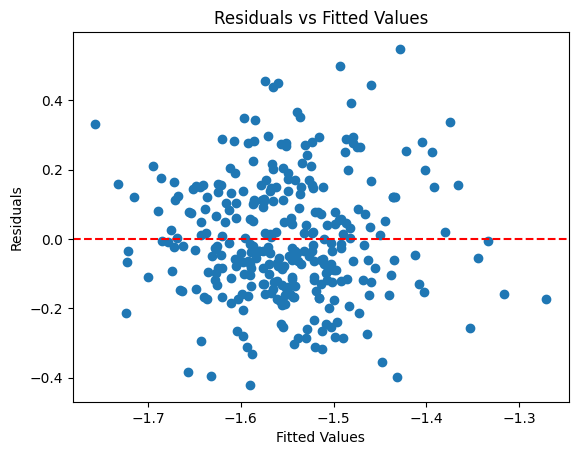

In [7]:
import matplotlib.pyplot as plt

fitted_values = results.fittedvalues
residuals = results.resid

plt.scatter(fitted_values, residuals)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.title('Residuals vs Fitted Values')
plt.show()


<Figure size 2000x2000 with 0 Axes>

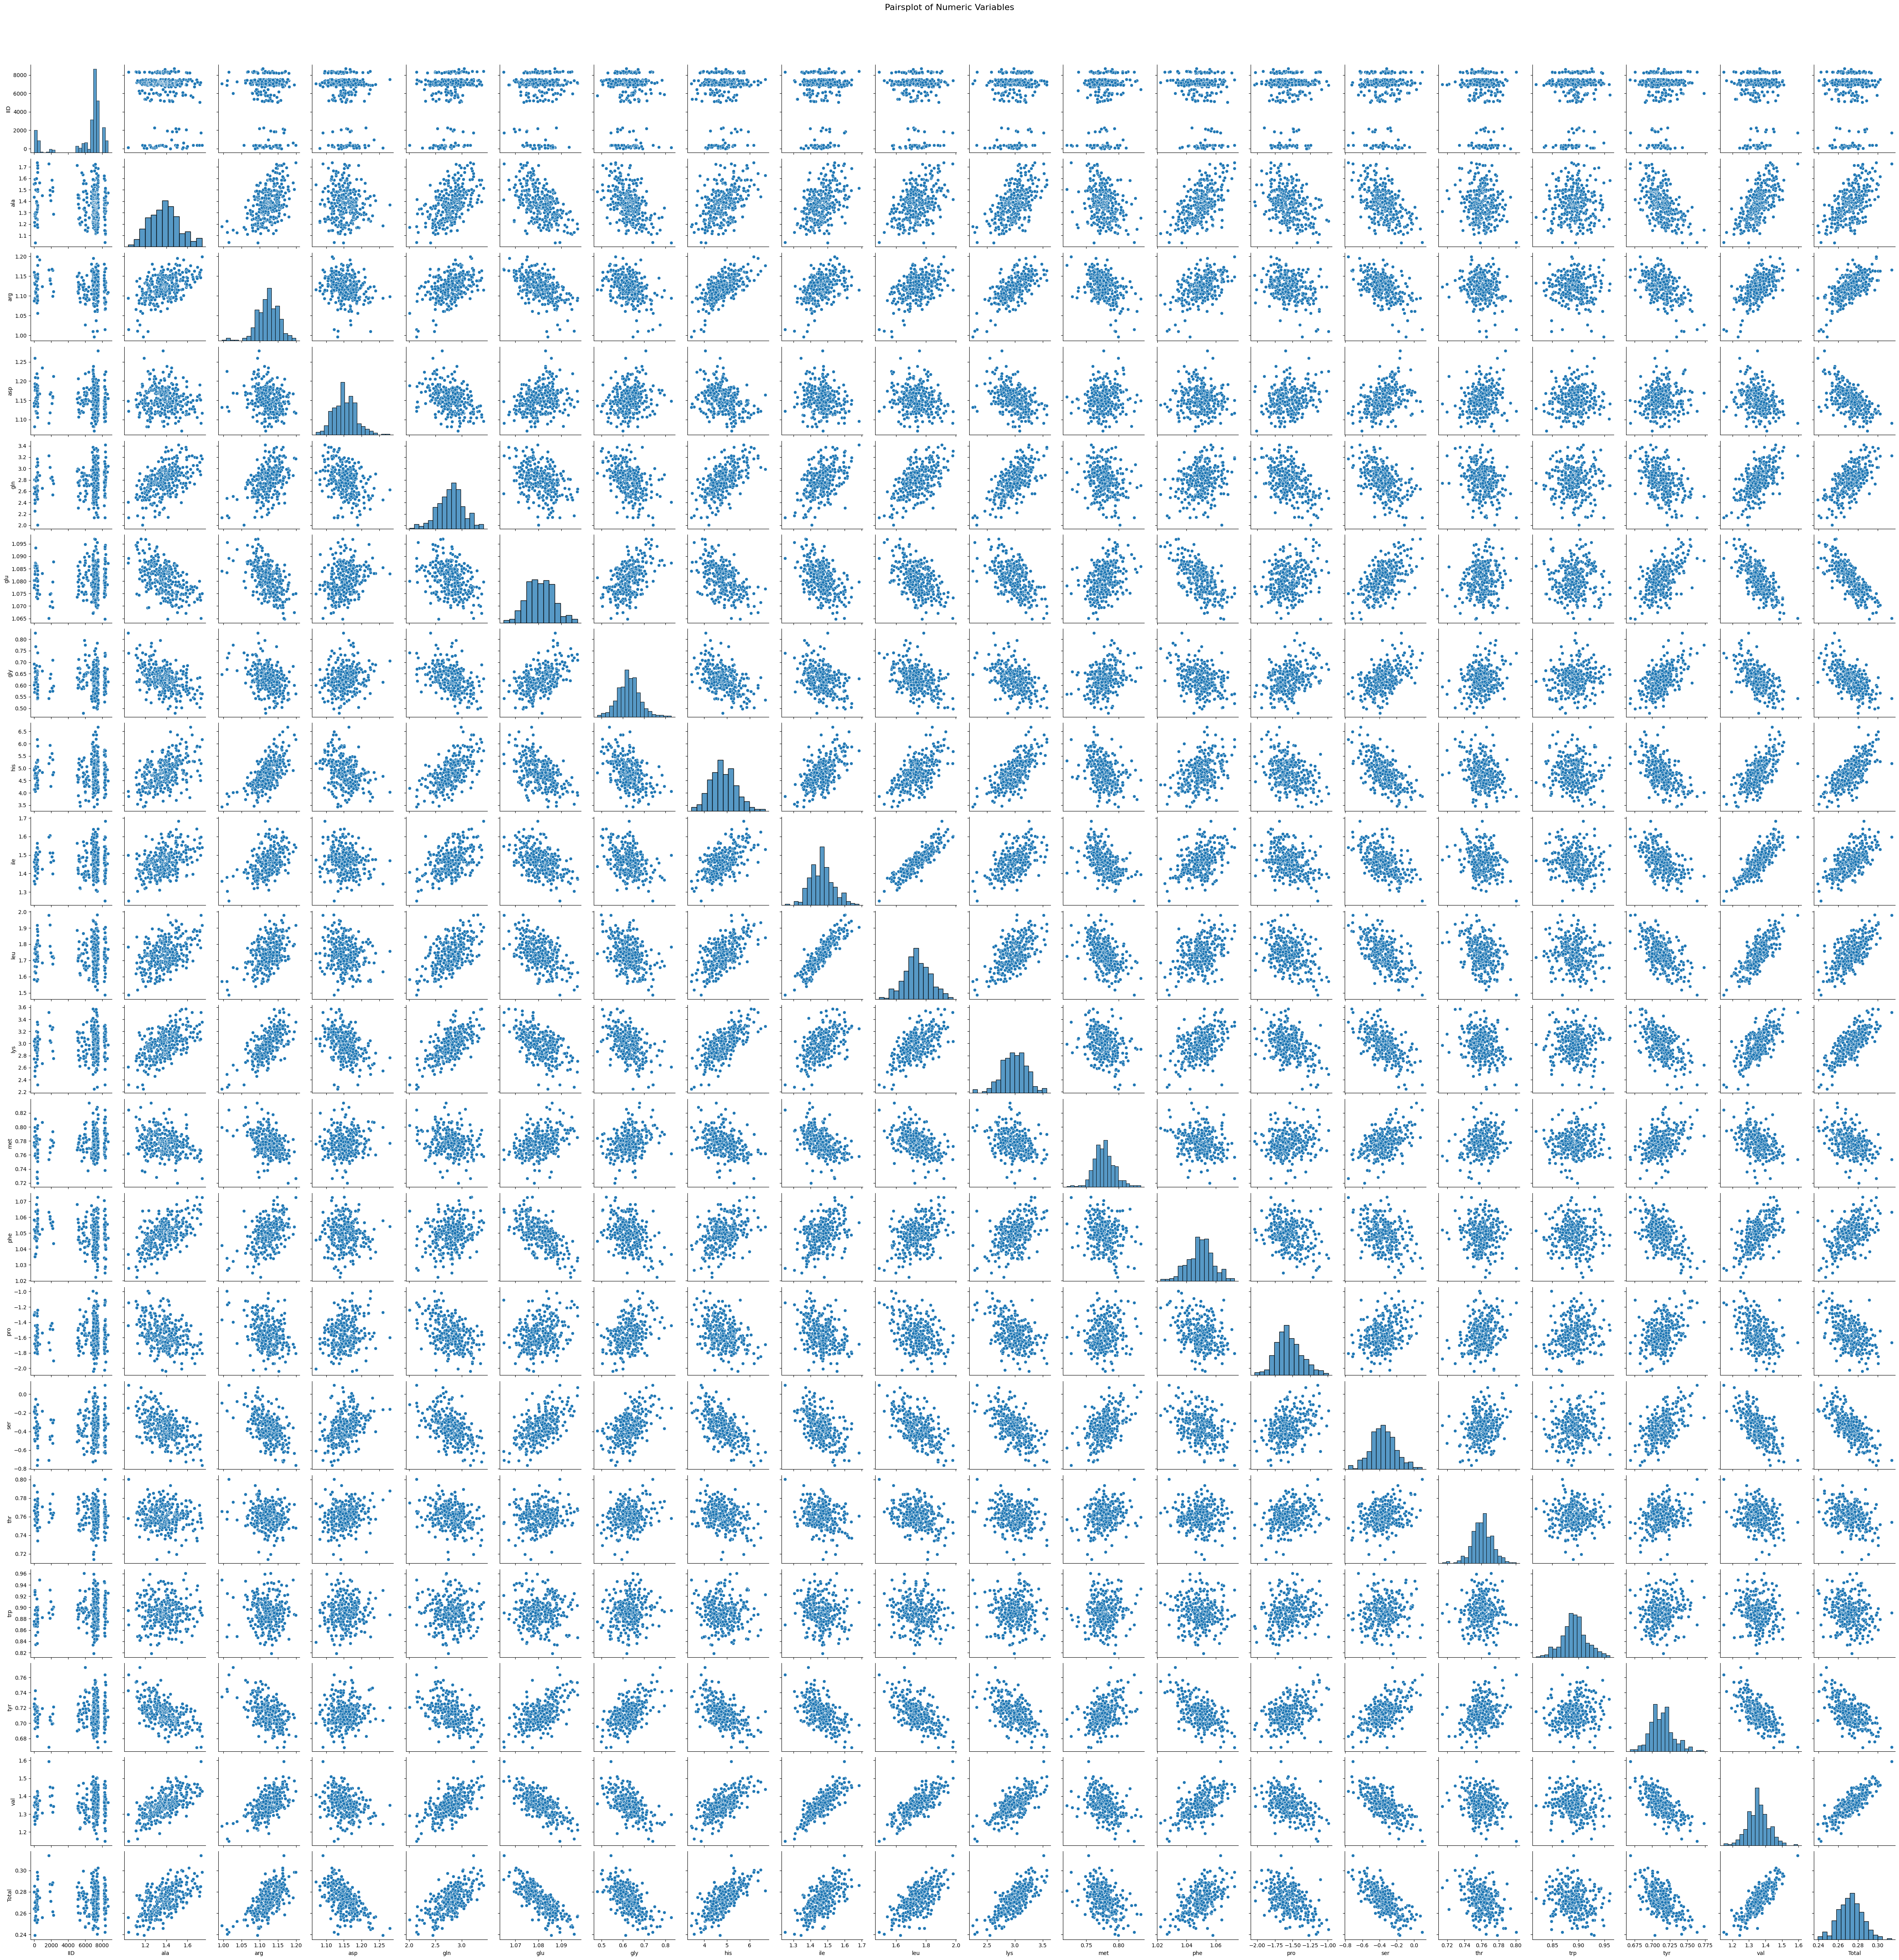

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select only numeric columns for the pairplot to avoid errors with categorical ID columns
numeric_cols = data.select_dtypes(include=['float64', 'int64'])

# Generate the pairplot (using a subset of columns or downsampling if the dataset is very large,
# but with 21 columns and 312 rows, a direct pairplot should render well)
plt.figure(figsize=(20, 20))
sns.pairplot(numeric_cols.dropna())
plt.suptitle('Pairsplot of Numeric Variables', y=1.02, fontsize=16)
plt.show()

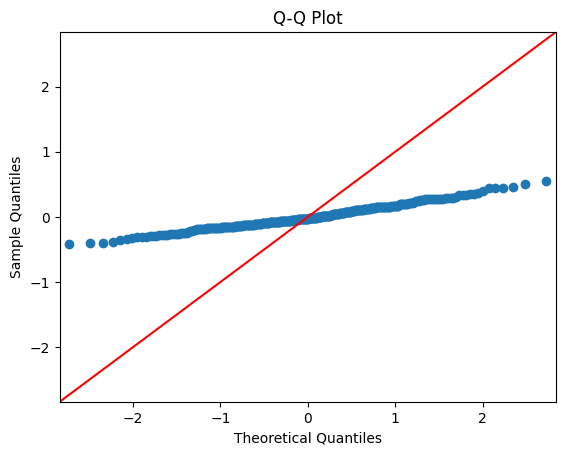

In [8]:
sm.qqplot(residuals, line='45')
plt.title('Q-Q Plot')
plt.show()


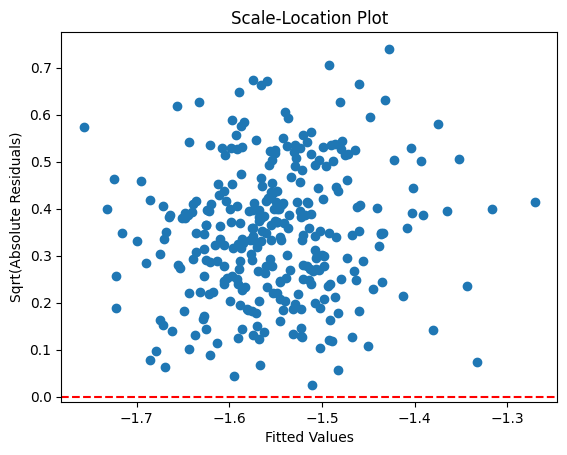

In [9]:
import numpy as np

sqrt_residuals = np.sqrt(np.abs(residuals))

plt.scatter(fitted_values, sqrt_residuals)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Fitted Values')
plt.ylabel('Sqrt(Absolute Residuals)')
plt.title('Scale-Location Plot')
plt.show()


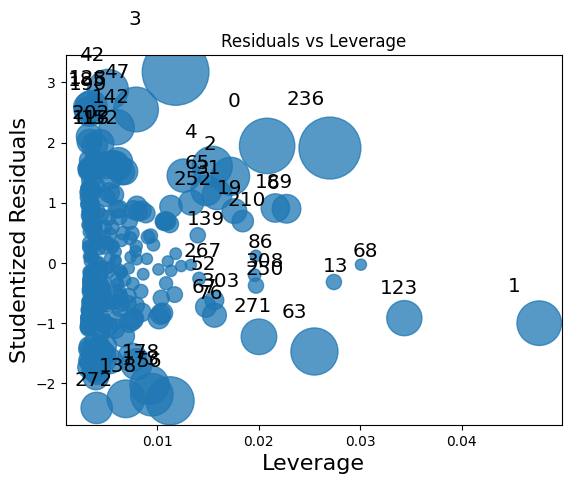

In [10]:
sm.graphics.influence_plot(results)
plt.title('Residuals vs Leverage')
plt.show()


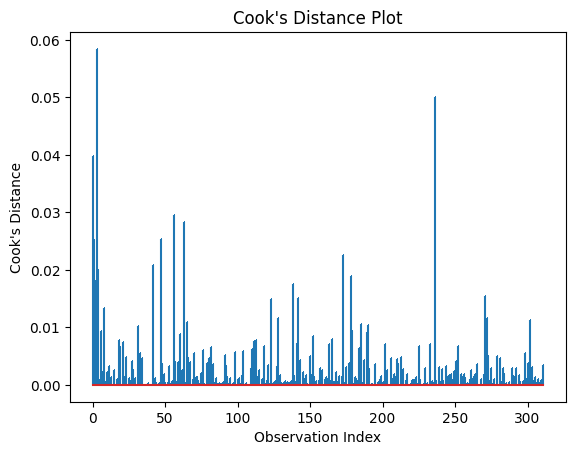

In [11]:
influence = results.get_influence()
cooks_d = influence.cooks_distance[0]

plt.stem(np.arange(len(cooks_d)), cooks_d, markerfmt=",")
plt.xlabel('Observation Index')
plt.ylabel("Cook's Distance")
plt.title("Cook's Distance Plot")
plt.show()


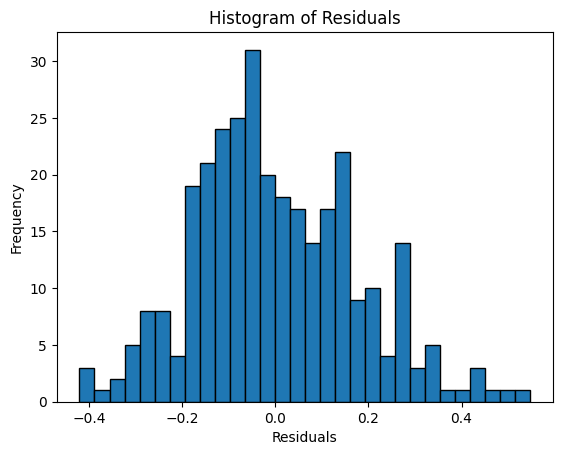

In [12]:
plt.hist(residuals, bins=30, edgecolor='k')
plt.xlabel('Residuals')
plt.ylabel('Frequency')
plt.title('Histogram of Residuals')
plt.show()


/tmp/ipykernel_1217/3286848037.py:1: FutureWarning: plot_partregress currently returns a bare figure when ret_coords=False. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a PartRegressPlotResult NamedTuple, which also carries the coordinates. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  sm.graphics.plot_partregress('his', 'gly', [], data=data, obs_labels=False)


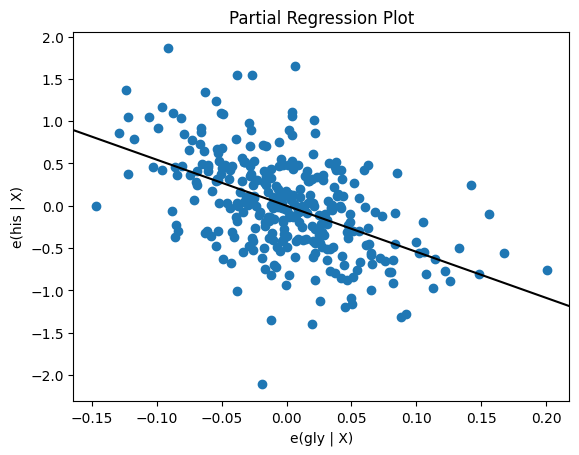

In [13]:
sm.graphics.plot_partregress('his', 'gly', [], data=data, obs_labels=False)
plt.show()


In [15]:
# Drop categorical/ID columns if they are not features, and separate the target 'pro'
X = data.select_dtypes(include=['float64', 'int64']).drop(columns=['pro'], errors='ignore')
y = data['pro']

# Display the shapes of the newly generated variables
print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")

# Display the first few columns of X to verify
display(X.head())

X shape: (312, 19)
y shape: (312,)


,IID,ala,arg,asp,gln,glu,gly,his,ile,leu,lys,met,phe,ser,thr,trp,tyr,val,Total
0,6911,0.921413,1.038291,NaN,2.173042,1.098548,0.753047,3.935519,1.375466,1.601335,2.510476,0.769337,1.036050,-0.032452,0.806368,0.871063,0.760870,1.189714,0.227618
1,126,1.037377,1.094559,1.148481,2.405929,1.087352,0.827303,4.064795,1.499667,1.783630,2.614253,0.761577,1.036635,-0.148576,0.758386,0.894489,0.742909,1.297623,0.256062
2,8323,1.039818,1.015439,1.121777,2.137448,1.089259,0.739376,3.854021,1.251738,1.486868,2.318302,0.824087,1.027972,0.097380,0.800357,0.869364,0.763795,1.147919,0.242245
3,6932,1.061223,NaN,1.109104,2.303847,1.094831,0.714998,3.506777,1.336352,1.567024,2.405698,0.841715,1.031585,0.061057,0.761195,0.907860,0.773125,1.247382,0.239451
4,8365,1.110620,1.066198,1.152403,2.491220,1.094461,0.731903,4.629195,1.375649,1.619123,2.714834,0.814395,1.028737,-0.125687,0.751212,0.896938,0.753940,1.208407,0.248345


Mean LOOCV MSE: 0.03125


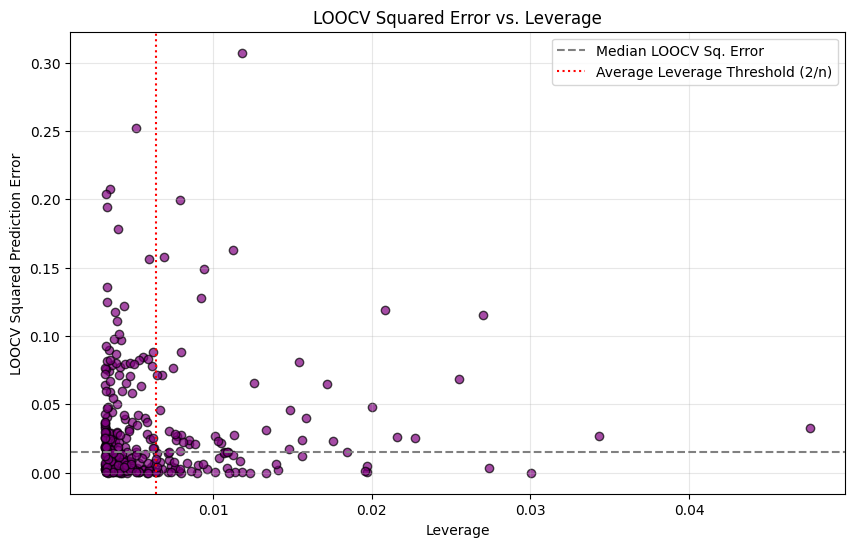

In [18]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

# 1. Prepare data (handling any NaN values in gly or pro to match the OLS fit)
clean_data = data[['gly', 'pro']].dropna()
X_simple = sm.add_constant(clean_data['gly'])
y_simple = clean_data['pro']
n = len(clean_data)

# Fit the full model to get leverages
full_model = sm.OLS(y_simple, X_simple).fit()
influence_full = full_model.get_influence()
leverage = influence_full.hat_matrix_diag

# 2. Perform Leave-One-Out Cross-Validation (LOOCV)
loo_predictions = []
loo_errors = []

for i in range(n):
    # Exclude the i-th observation using drop
    X_train = X_simple.drop(X_simple.index[i])
    y_train = y_simple.drop(y_simple.index[i])

    # Test on the i-th observation
    X_test = X_simple.iloc[[i]]
    y_test = y_simple.iloc[i]

    # Fit model on training subset
    model_i = sm.OLS(y_train, X_train).fit()

    # Predict and record error (using .values[0] to avoid index mismatch errors)
    pred_i = model_i.predict(X_test).values[0]
    loo_predictions.append(pred_i)
    loo_errors.append(y_test - pred_i)

loo_errors = np.array(loo_errors)
squared_loo_errors = loo_errors ** 2
mean_loocv_mse = np.mean(squared_loo_errors)

print(f"Mean LOOCV MSE: {mean_loocv_mse:.5f}")

# 3. Plot LOOCV Squared Prediction Error vs. Leverage
plt.figure(figsize=(10, 6))
plt.scatter(leverage, squared_loo_errors, alpha=0.7, color='purple', edgecolors='k')
plt.axhline(y=np.median(squared_loo_errors), color='gray', linestyle='--', label='Median LOOCV Sq. Error')
plt.axvline(x=2 / n, color='red', linestyle=':', label='Average Leverage Threshold (2/n)')

plt.xlabel('Leverage')
plt.ylabel('LOOCV Squared Prediction Error')
plt.title('LOOCV Squared Error vs. Leverage')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Number of identified Out-of-Distribution (OOD) samples: 18 out of 302


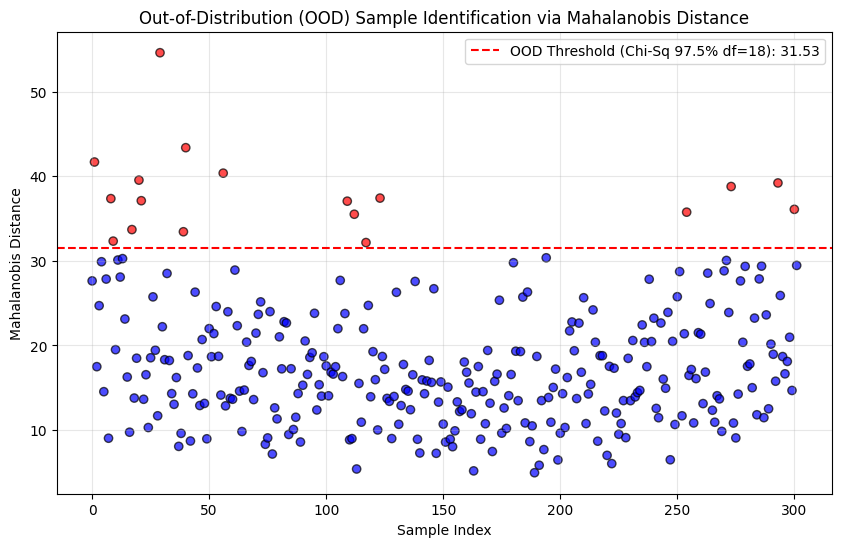


Flagged OOD Samples:


,IID,ala,arg,asp,gln,glu,gly,his,ile,leu,...,met,phe,ser,thr,trp,tyr,val,Total,mahalanobis,is_OOD
2,8323,1.039818,1.015439,1.121777,2.137448,1.089259,0.739376,3.854021,1.251738,1.486868,...,0.824087,1.027972,0.097380,0.800357,0.869364,0.763795,1.147919,0.242245,41.682392,True
10,8354,1.140657,1.081539,1.106457,2.793642,1.074373,0.617196,4.124801,1.496657,1.733158,...,0.768096,1.040356,-0.461142,0.763856,0.903226,0.719222,1.327871,0.273717,37.355905,True
11,8296,1.144750,1.123306,1.114278,2.494175,1.081022,0.624904,4.934802,1.415597,1.659773,...,0.811278,1.053304,-0.296998,0.738211,0.850033,0.700259,1.296184,0.272653,32.332246,True
19,379,1.172076,1.056274,1.188304,2.008378,1.079972,0.740904,4.198762,1.407281,1.583567,...,0.802152,1.063927,-0.111696,0.775073,0.900694,0.720937,1.291753,0.253944,33.694712,True
22,7064,1.180510,0.996698,1.132058,2.136454,1.084085,0.646653,3.428425,1.358412,1.571511,...,0.799670,1.042304,-0.092210,0.765866,0.948929,0.734686,1.234301,0.248492,39.540953,True


In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2

# 1. Clean feature matrix X (drop any rows with missing values for OOD detection)
X_clean = X.dropna()

# 2. Calculate Mahalanobis Distance
def mahalanobis_distance(df):
    x_minus_mu = df - df.mean()
    cov_matrix = df.cov()
    inv_cov_matrix = np.linalg.inv(cov_matrix)
    left = np.dot(x_minus_mu, inv_cov_matrix)
    mahal = np.dot(left, x_minus_mu.T).diagonal()
    return mahal

# Compute distances
X_clean = X_clean.copy()
X_clean['mahalanobis'] = mahalanobis_distance(X_clean.drop(columns=['IID'], errors='ignore'))

# 3. Determine threshold for OOD (using Chi-Square distribution with degrees of freedom = number of features)
df_keys = X_clean.drop(columns=['IID', 'mahalanobis'], errors='ignore').shape[1]
threshold = chi2.ppf(0.975, df=df_keys) # 97.5% confidence threshold

# Mark outliers / OOD samples
X_clean['is_OOD'] = X_clean['mahalanobis'] > threshold
num_ood = X_clean['is_OOD'].sum()
print(f"Number of identified Out-of-Distribution (OOD) samples: {num_ood} out of {len(X_clean)}")

# 4. Plot Mahalanobis Distances
plt.figure(figsize=(10, 6))
colors = X_clean['is_OOD'].map({True: 'red', False: 'blue'})
plt.scatter(range(len(X_clean)), X_clean['mahalanobis'], c=colors, alpha=0.7, edgecolors='k')
plt.axhline(y=threshold, color='red', linestyle='--', label=f'OOD Threshold (Chi-Sq 97.5% df={df_keys}): {threshold:.2f}')
plt.xlabel('Sample Index')
plt.ylabel('Mahalanobis Distance')
plt.title('Out-of-Distribution (OOD) Sample Identification via Mahalanobis Distance')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Display some flagged OOD samples
if num_ood > 0:
    print("\nFlagged OOD Samples:")
    display(X_clean[X_clean['is_OOD']].head())
else:
    print("\nNo extreme OOD samples detected with the current threshold.")

In-Distribution (Non-OOD) Samples: 284
Out-of-Distribution (OOD) Samples: 18

--- Mean Profiles Comparison (Ordered by Largest Absolute Difference) ---


,In-Distribution Mean,OOD Mean,Abs Difference
his,4.843618,4.672770,0.170847
lys,2.990152,2.871630,0.118522
gln,2.795393,2.689615,0.105778
ser,-0.359266,-0.281234,0.078032
ala,1.385704,1.313495,0.072208
leu,1.744782,1.688985,0.055798
ile,1.466881,1.434835,0.032047
val,1.355732,1.328267,0.027465
arg,1.123523,1.099055,0.024468
asp,1.153013,1.144995,0.008018


/tmp/ipykernel_1217/607645280.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1217/607645280.py:34: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[idx].set_xticklabels(['In-Distribution', 'OOD'])
/tmp/ipykernel_1217/607645280.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1217/607645280.py:34: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[idx].set_xticklabels(['In-Distribution', 'OOD'])
/tmp/ipykernel_1217/607645280.py:30: FutureWarning: 

Passing `palette` without assignin

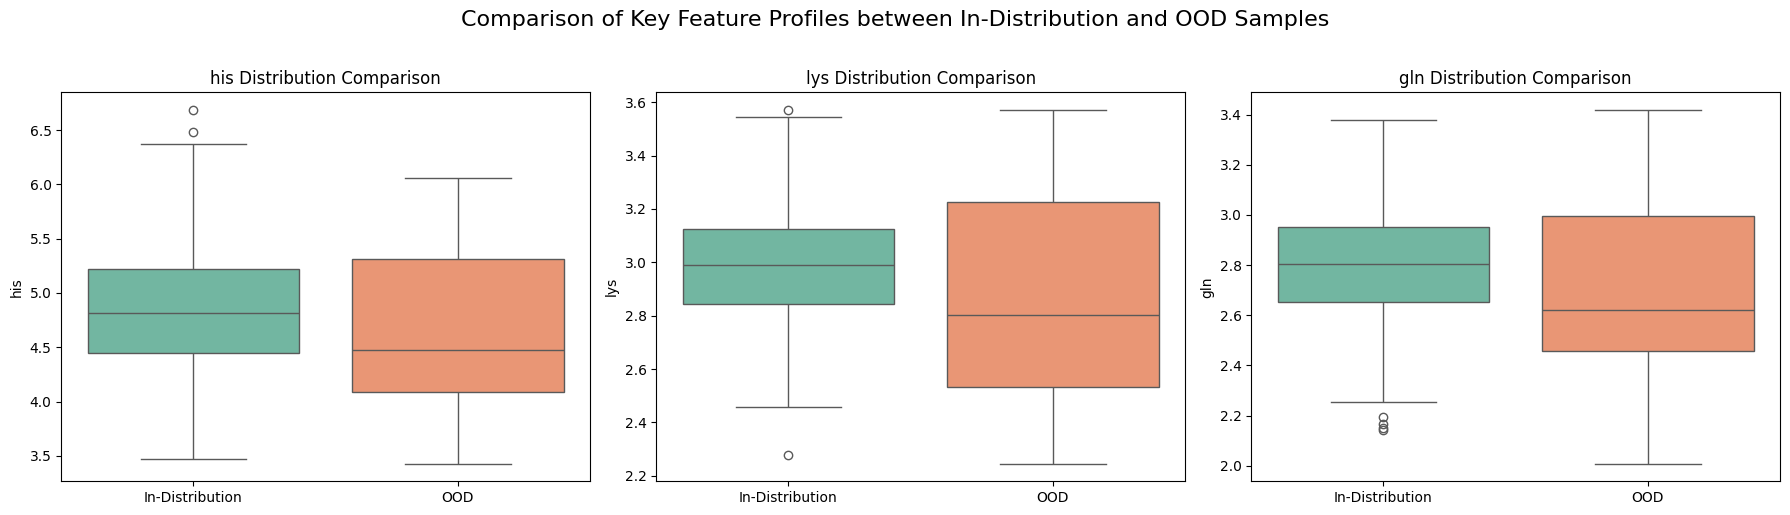

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Split the dataset into OOD and In-Distribution (non-OOD) categories
ood_samples = X_clean[X_clean['is_OOD'] == True]
in_dist_samples = X_clean[X_clean['is_OOD'] == False]

print(f"In-Distribution (Non-OOD) Samples: {len(in_dist_samples)}")
print(f"Out-of-Distribution (OOD) Samples: {len(ood_samples)}")

# 2. Compare feature means between the two categories
features_to_compare = X_clean.drop(columns=['IID', 'mahalanobis', 'is_OOD'], errors='ignore').columns

mean_comparison = pd.DataFrame({
    'In-Distribution Mean': in_dist_samples[features_to_compare].mean(),
    'OOD Mean': ood_samples[features_to_compare].mean(),
    'Abs Difference': (in_dist_samples[features_to_compare].mean() - ood_samples[features_to_compare].mean()).abs()
}).sort_values(by='Abs Difference', ascending=False)

print(
    '\n--- Mean Profiles Comparison (Ordered by Largest Absolute Difference) ---'
)
display(mean_comparison)

# 3. Visualize distributions for the top 3 differing features
top_3_diff_features = mean_comparison.index[:3].tolist()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for idx, feature in enumerate(top_3_diff_features):
    sns.boxplot(
        data=X_clean, x='is_OOD', y=feature, ax=axes[idx], palette='Set2'
    )
    axes[idx].set_title(f'{feature} Distribution Comparison')
    axes[idx].set_xticklabels(['In-Distribution', 'OOD'])
    axes[idx].set_xlabel('')

plt.suptitle(
    'Comparison of Key Feature Profiles between In-Distribution and OOD Samples',
    fontsize=16,
    y=1.02,
)
plt.tight_layout()
plt.show()